# 02 — Preprocessing

Turns the raw CRMLS files into a clean, model-ready single-family dataset and chooses the training-window length.

1. Handle missing and invalid values (drop / impute / flag)
2. Encode categorical fields as numbers
3. Normalise numeric features where the model needs it
4. Time-based split: **test = most recent month**, **train = the X months immediately before it**, with X tuned

Cleaning and encoding logic lives in [`src/preprocessing.py`](src/preprocessing.py) so later notebooks reuse it. Outputs go to `Data/processed/` (git-ignored).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from threadpoolctl import threadpool_limits

sys.path.insert(0, "src")
import preprocessing as pp

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

OUT_DIR = Path("Data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load raw data

In [2]:
raw = pp.load_raw("Data")
print(f"{len(raw):,} rows, {raw.shape[1]} columns loaded")

794,271 rows, 33 columns loaded


## 2. Missing and invalid values

Missingness in the single-family subset, before cleaning:

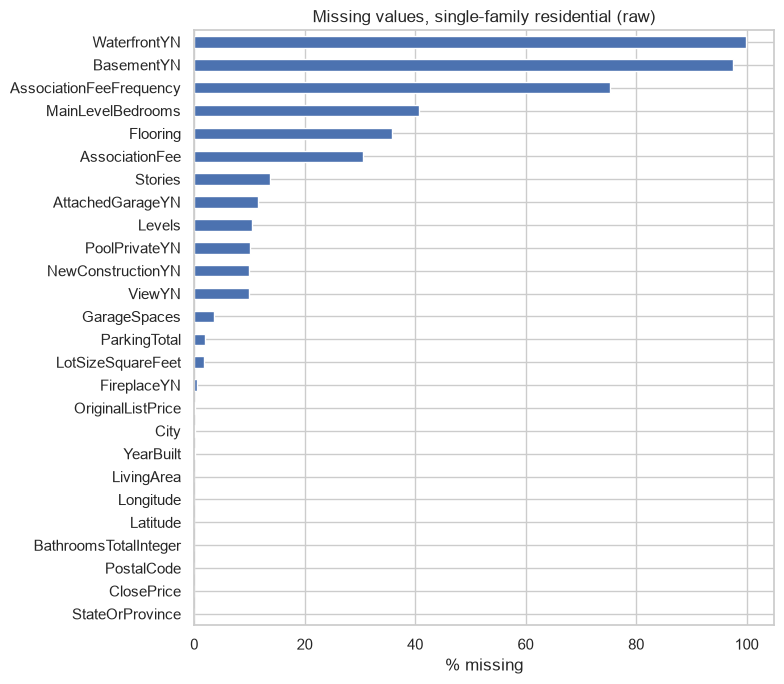

In [3]:
sfr_raw = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")]
miss = sfr_raw.isna().mean().mul(100).sort_values(ascending=False)
ax = miss[miss > 0].plot.barh(figsize=(8, 7))
ax.invert_yaxis()
ax.set_xlabel("% missing")
ax.set_title("Missing values, single-family residential (raw)")
plt.tight_layout()

### Decisions

| Field(s) | Issue | Decision |
|---|---|---|
| `ClosePrice` (target) | missing or outside \$50k–\$30M | **Drop row**: can't train on a wrong label |
| `LivingArea` | 0.1% missing / implausible | **Drop row**: strongest predictor, almost never missing |
| Duplicate `ListingKey`, non-CA state | appear in several files / out of area | **Drop row** |
| Beds, baths, lot size, year built, garage, parking, HOA fee, lat/lon | missing or implausible (e.g. 0 beds, 175 baths, lot > 100 acres) | Set implausible values to NaN → **impute with training-window median** + **`_missing` flag** |
| `Stories` (14%), `MainLevelBedrooms` (41%) | missing | **Impute + flag**: the flag lets the model learn whether missingness matters |
| Y/N fields (`ViewYN`, `PoolPrivateYN`, …) | ~10% missing | **Fill 0 + flag** |
| `BasementYN`, `WaterfrontYN` | only ever `True` or blank | **Blank → 0** (absence means no) |
| `Levels`, `Flooring` | 10–36% missing | **Own "missing" category** |
| `TaxAnnualAmount`, `FireplacesTotal`, `CoveredSpaces`, school districts, … | 94–100% missing | **Drop column** |
| Agent/office names, emails, addresses, IDs | not predictive / personal data | **Drop column** |
| `DaysOnMarket`, contract dates, `ListPrice` | only known at/after sale, or a near-copy of the target | **Excluded from features** (list prices kept in the CSV for reference) |

Medians are fit **only on the training window inside the model pipeline**, not on the full dataset, so no information from the test month leaks into training.

In [4]:
df, clean_log = pp.clean(raw)
clean_log.to_frame().assign(removed=lambda t: -t["rows"].diff()).fillna({"removed": 0}).astype(int)

,rows,removed
raw rows,794271,0
single-family residential,399157,395114
after dropping duplicate listings,398881,276
after keeping CA with a close date,398854,27
"after ClosePrice in $50,000-$30,000,000",398647,207
after requiring valid LivingArea,398249,398
final cleaned rows,398249,0


In [5]:
remaining = df.isna().mean().mul(100)
remaining[remaining > 0].sort_values(ascending=False).to_frame("% missing (imputed in pipeline)")

,% missing (imputed in pipeline)
MainLevelBedrooms,40.678
AssociationFeeMonthly,30.593
Stories,13.671
GarageSpaces,3.615
ParkingTotal,1.999
LotSizeSquareFeet,1.965
OriginalListPrice,0.196
Latitude,0.069
Longitude,0.069
YearBuilt,0.062


## 3. Encoding categorical fields

| Field | Cardinality | Encoding |
|---|---|---|
| Y/N fields | 2 | 0 / 1 |
| `Levels` | ~18 | One-hot: One, Two, ThreeOrMore, MultiSplit, Other, missing |
| `CountyOrParish` | 64 | One-hot for the 12 largest counties + Other |
| `Flooring` | 340 combinations | Multi-hot: one indicator per material (Carpet, Tile, Wood, …) |
| `AssociationFeeFrequency` | 4 | Used to convert `AssociationFee` to a monthly amount |
| `PostalCode`, `City` | ~3,700 / ~1,150 | **Target encoding** (mean log-price, cross-fitted on the training window only) |
| `CloseDate` | — | `close_month` (seasonality) and `close_month_index` (trend) |

One-hot encoding thousands of zip codes would create a huge sparse matrix, so the location codes are target-encoded. Because target encoding uses the target, it is fit inside the pipeline on training rows only.

In [6]:
groups = {
    "numeric": [c for c in pp.NUMERIC_FEATURES if c in df],
    "binary Y/N": pp.BINARY_COLS + pp.TRUE_OR_MISSING_COLS + ["has_hoa"],
    "missing flags": [c for c in df if c.endswith("_missing")],
    "one-hot Levels": [c for c in df if c.startswith("Levels_") and c != "Levels_missing"],
    "one-hot County": [c for c in df if c.startswith("County_")],
    "multi-hot Flooring": [c for c in df if c.startswith("Flooring_") and c != "Flooring_missing"],
    "target-encoded": pp.TARGET_ENCODED,
}
features = pp.feature_columns(df)
print(f"{len(features)} feature columns\n")
for name, cols in groups.items():
    print(f"{name:20s} {len(cols):3d}  {', '.join(cols)}")

63 feature columns

numeric               14  LivingArea, BedroomsTotal, BathroomsTotalInteger, LotSizeSquareFeet, YearBuilt, Latitude, Longitude, GarageSpaces, ParkingTotal, Stories, MainLevelBedrooms, AssociationFeeMonthly, close_month_index, close_month
binary Y/N             8  ViewYN, PoolPrivateYN, FireplaceYN, NewConstructionYN, AttachedGarageYN, BasementYN, WaterfrontYN, has_hoa
missing flags         15  LotSizeSquareFeet_missing, YearBuilt_missing, GarageSpaces_missing, ParkingTotal_missing, Stories_missing, MainLevelBedrooms_missing, AssociationFeeMonthly_missing, Latitude_missing, ViewYN_missing, PoolPrivateYN_missing, FireplaceYN_missing, NewConstructionYN_missing, AttachedGarageYN_missing, Levels_missing, Flooring_missing
one-hot Levels         5  Levels_MultiSplit, Levels_One, Levels_Other, Levels_ThreeOrMore, Levels_Two
one-hot County        13  County_Alameda, County_Contra_Costa, County_Los_Angeles, County_Monterey, County_Orange, County_Other, County_Riverside, County

## 4. Normalisation

- **Target:** `ClosePrice` is modelled as `log(ClosePrice)`; skewness drops from ~6.5 (after removing invalid prices; ~138 before) to ~0.5. Predictions are converted back to dollars for evaluation.
- **Tree models** (gradient boosting) are unaffected by monotonic rescaling, so features are left on their natural scale.
- **Linear models** (Ridge) need it: long-tailed features are `log1p`-transformed, then all numeric features are standardised (mean 0, std 1). The scaler is fit on the training window only.

The effect of the log transform on the skewed features:

In [7]:
skew = pd.DataFrame({
    "raw skew": df[pp.SKEWED_FEATURES + [pp.TARGET]].skew(),
    "log1p skew": np.log1p(df[pp.SKEWED_FEATURES + [pp.TARGET]]).skew(),
})
skew

,raw skew,log1p skew
LivingArea,2.809,0.327
LotSizeSquareFeet,20.921,2.113
AssociationFeeMonthly,6.320,0.731
ParkingTotal,3.478,-0.143
ClosePrice,6.483,0.501


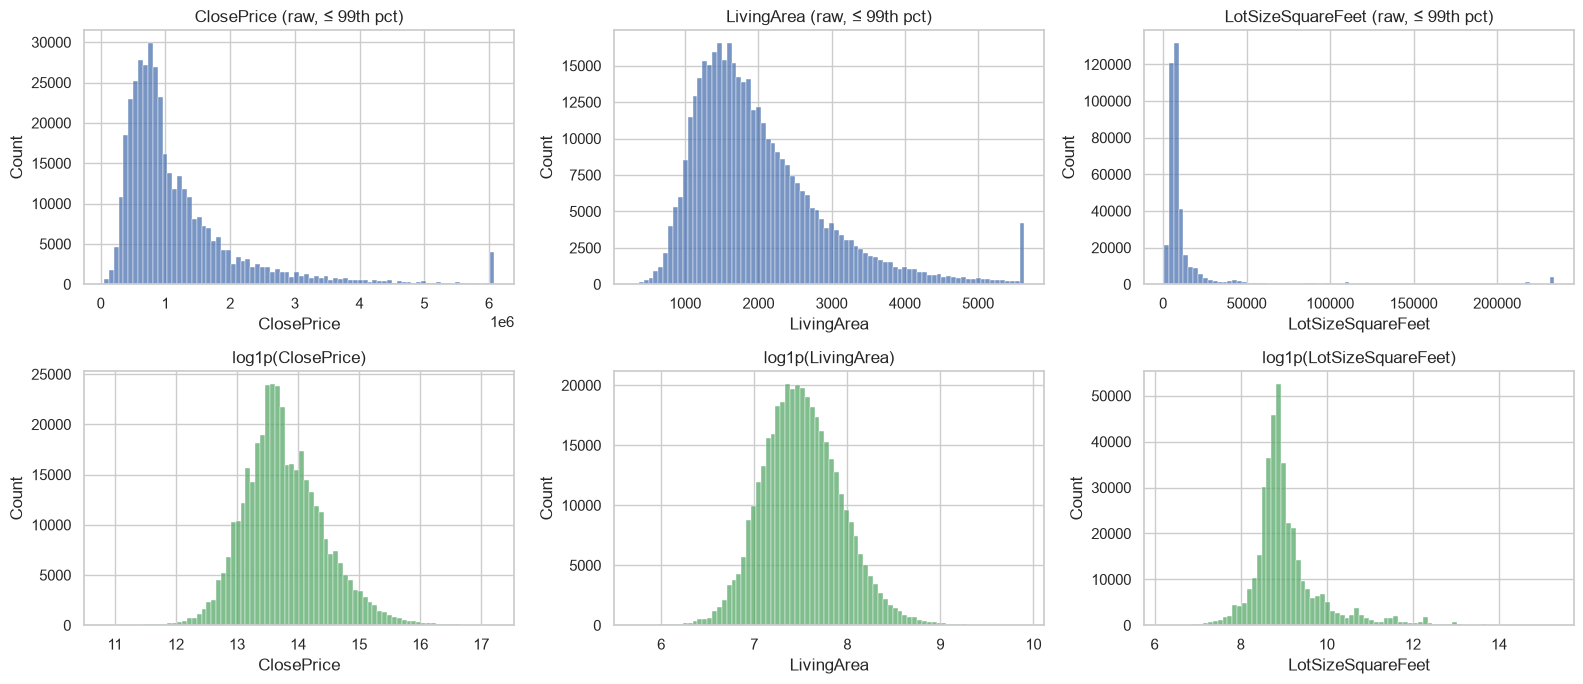

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for (col, ax_raw, ax_log) in zip(["ClosePrice", "LivingArea", "LotSizeSquareFeet"], axes[0], axes[1]):
    s = df[col].dropna()
    sns.histplot(s.clip(upper=s.quantile(0.99)), bins=80, ax=ax_raw)
    ax_raw.set_title(f"{col} (raw, ≤ 99th pct)")
    sns.histplot(np.log1p(s), bins=80, ax=ax_log, color="C2")
    ax_log.set_title(f"log1p({col})")
plt.tight_layout()

## 5. Save cleaned dataset

The cleaned CSV holds filtered rows and all encodings that don't depend on the target. NaNs are kept for numeric features (with `_missing` flags), because the imputation medians depend on which training window is used.

In [9]:
CLEAN_PATH = OUT_DIR / "cleaned_sfr.csv"
df.to_csv(CLEAN_PATH, index=False)
print(f"Saved {CLEAN_PATH}  ({len(df):,} rows x {df.shape[1]} cols, {CLEAN_PATH.stat().st_size / 1e6:.0f} MB)")

Saved Data\processed\cleaned_sfr.csv  (398,249 rows x 69 cols, 98 MB)


## 6. Train/test split

The test set is the most recent month in the data. Sales per month show that the 2022–2023 file barely covers 2022 through April 2023; consistent coverage starts around mid-2023, which caps how far back a training window can usefully reach.

Test month: 2026-05 (12,003 sales)


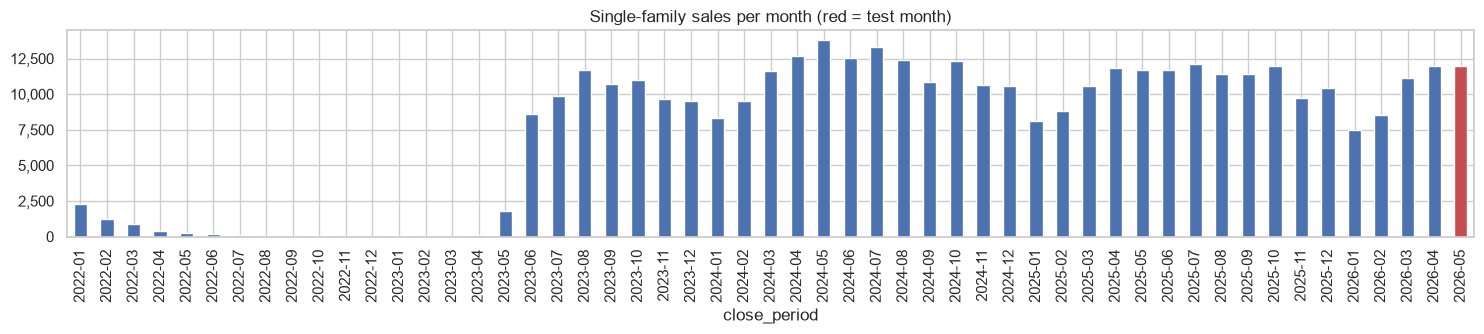

In [10]:
monthly_counts = df.groupby("close_period").size()
TEST_PERIOD = monthly_counts.index.max()
print("Test month:", TEST_PERIOD, f"({monthly_counts[TEST_PERIOD]:,} sales)")

ax = monthly_counts.plot.bar(figsize=(15, 3.5), color=["C3" if p == TEST_PERIOD else "C0" for p in monthly_counts.index])
ax.set_title("Single-family sales per month (red = test month)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()

## 7. Choosing the training-window length X

**Trade-off:** a longer window gives more training rows, but older sales reflect older market conditions.

**Method:** X must not be chosen by looking at the test month, or the test score stops being an honest estimate. Instead, we run a rolling backtest on the **3 months before the test month**. For each validation month V and each candidate X, train on the X months before V and score on V. The X with the lowest mean validation MAPE wins.

Two models are compared: gradient boosting (main) and Ridge (a linear baseline that uses the scaled features).

In [11]:
X_GRID = [1, 2, 3, 6, 9, 12, 18, 24, 30]
N_VAL = 3
test_p = pd.Period(TEST_PERIOD, "M")
VAL_PERIODS = [str(test_p - k) for k in range(N_VAL, 0, -1)]
print("Validation months:", VAL_PERIODS)

def run(target_period, x, kind):
    train, test = pp.time_split(df, target_period, x)
    model = pp.make_model(kind, features).fit(train[features], train[pp.TARGET])
    return {"period": target_period, "X": x, "model": kind, "n_train": len(train),
            **pp.evaluate(test[pp.TARGET].to_numpy(), model.predict(test[features]))}

Validation months: ['2026-02', '2026-03', '2026-04']


In [12]:
%%time
rows = []
with threadpool_limits(8):
    for kind in ["hgb", "ridge"]:
        for x in X_GRID:
            for v in VAL_PERIODS:
                rows.append(run(v, x, kind))
val = pd.DataFrame(rows)

CPU times: total: 18min 35s
Wall time: 5min 23s


In [13]:
val_summary = (val.groupby(["model", "X"])
                  .agg(n_train=("n_train", "mean"), MAPE=("MAPE", "mean"), MAPE_std=("MAPE", "std"),
                       MdAPE=("MdAPE", "mean"), within_10pct=("within_10pct", "mean"), R2=("R2", "mean"))
                  .reset_index())
val_summary["n_train"] = val_summary["n_train"].round().astype(int)
val_summary

,model,X,n_train,MAPE,MAPE_std,MdAPE,within_10pct,R2
0,hgb,1,9051,14.365,0.585,9.737,51.016,0.802
1,hgb,2,17861,13.484,0.215,9.062,53.929,0.832
2,hgb,3,27064,13.137,0.252,8.837,54.741,0.836
3,hgb,6,60442,12.669,0.273,8.556,56.047,0.842
4,hgb,9,95649,12.387,0.275,8.445,56.766,0.853
5,hgb,12,129208,12.309,0.246,8.450,56.566,0.851
6,hgb,18,191713,12.321,0.193,8.337,57.148,0.855
7,hgb,24,266874,12.265,0.222,8.340,57.151,0.856
8,hgb,30,326659,12.235,0.231,8.342,57.310,0.857
9,ridge,1,9051,17.514,0.259,12.726,40.624,0.744


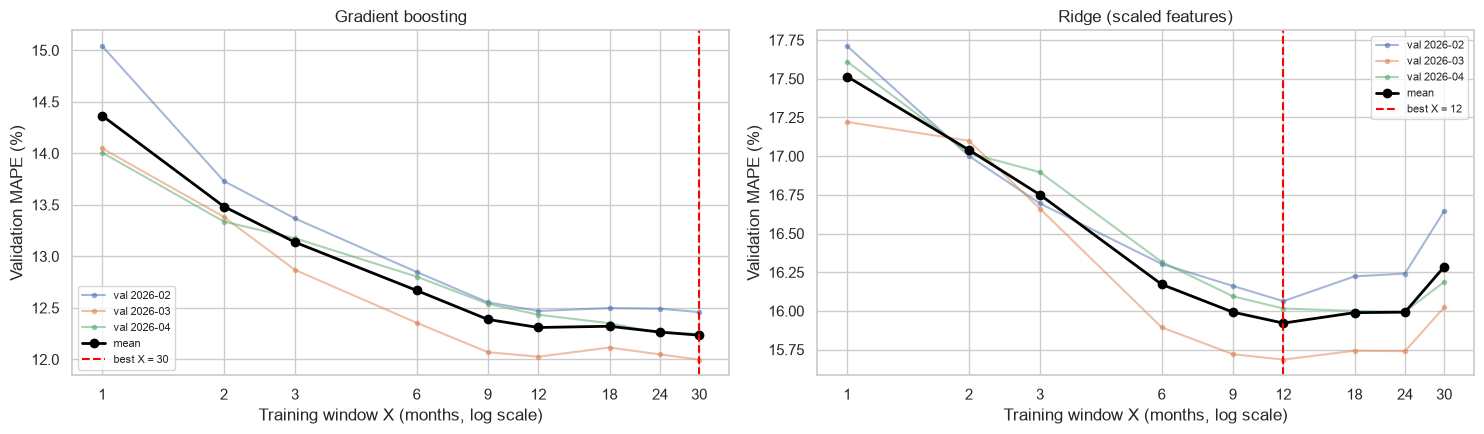

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for kind, ax in zip(["hgb", "ridge"], axes):
    d = val[val["model"] == kind]
    for v, g in d.groupby("period"):
        ax.plot(g["X"], g["MAPE"], marker=".", alpha=0.5, label=f"val {v}")
    s = val_summary[val_summary["model"] == kind]
    ax.plot(s["X"], s["MAPE"], marker="o", color="black", lw=2, label="mean")
    best = s.loc[s["MAPE"].idxmin()]
    ax.axvline(best["X"], color="red", ls="--", label=f"best X = {int(best['X'])}")
    ax.set_xscale("log")
    ax.set_xticks(X_GRID)
    ax.xaxis.set_major_formatter(mtick.ScalarFormatter())
    ax.set_xlabel("Training window X (months, log scale)")
    ax.set_ylabel("Validation MAPE (%)")
    ax.set_title({"hgb": "Gradient boosting", "ridge": "Ridge (scaled features)"}[kind])
    ax.legend(fontsize=8)
plt.tight_layout()

Very short windows clearly hurt. Past a certain point the curve flattens, so several windows score within noise of each other. To avoid over-reading small differences, we take the **smallest X whose mean validation MAPE is within 0.1 percentage points of the best**: the most recent data for essentially the same accuracy.

In [15]:
hgb_val = val_summary[val_summary["model"] == "hgb"].set_index("X")
best_mape = hgb_val["MAPE"].min()
BEST_X = int(hgb_val.index[hgb_val["MAPE"] <= best_mape + 0.1].min())
print(f"Lowest mean validation MAPE: {best_mape:.2f}% at X = {hgb_val['MAPE'].idxmin()}")
print(f"Chosen X = {BEST_X} months (validation MAPE {hgb_val.loc[BEST_X, 'MAPE']:.2f}%)")

Lowest mean validation MAPE: 12.23% at X = 30
Chosen X = 12 months (validation MAPE 12.31%)


**Result:** accuracy improves quickly from 1 to about 9–12 months, then plateaus: going from 12 to 30 months adds 2.5x the data but improves validation MAPE by less than 0.1 percentage points, which is smaller than the month-to-month spread. The linear model also bottoms out around 12 months and gets worse at 30, a sign that older price levels start to hurt a model that can't adapt to them. **X = 12** gives the most recent data at essentially the best accuracy.

### Test-month check

With X fixed, evaluate once on the held-out test month. The full test-month curve over all X is shown **for reference only**; it was not used to pick X.

In [16]:
%%time
with threadpool_limits(8):
    test_curve = pd.DataFrame([run(TEST_PERIOD, x, "hgb") for x in X_GRID])
test_curve.set_index("X")[["n_train", "MAPE", "MdAPE", "within_10pct", "R2"]]

CPU times: total: 3min 22s
Wall time: 27.4 s


,n_train,MAPE,MdAPE,within_10pct,R2
X,,,,,
1,12006,13.793,9.203,53.362,0.827
2,23164,13.143,8.900,54.828,0.839
3,31694,12.969,8.725,55.394,0.841
6,59302,12.589,8.512,56.286,0.860
9,94158,12.459,8.530,56.544,0.865
12,129645,12.284,8.362,56.836,0.869
18,190293,12.195,8.344,57.094,0.869
24,265524,12.159,8.320,57.211,0.871
30,326867,12.194,8.350,57.269,0.869


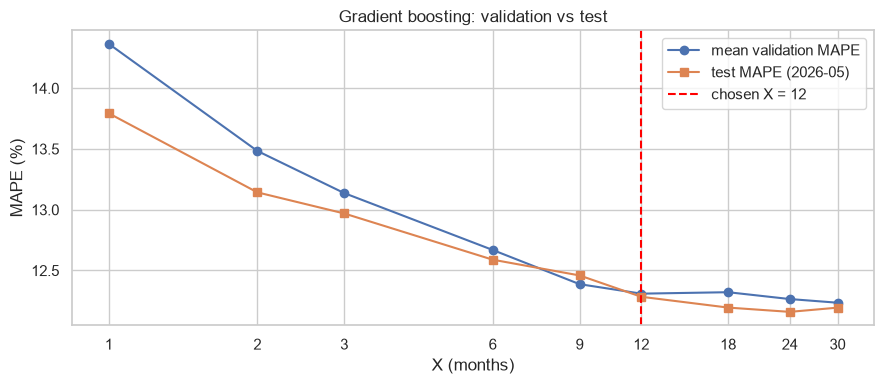

In [17]:
ax = hgb_val["MAPE"].plot(marker="o", label="mean validation MAPE", figsize=(9, 4))
test_curve.set_index("X")["MAPE"].plot(ax=ax, marker="s", label=f"test MAPE ({TEST_PERIOD})")
ax.axvline(BEST_X, color="red", ls="--", label=f"chosen X = {BEST_X}")
ax.set_xscale("log")
ax.set_xticks(X_GRID)
ax.xaxis.set_major_formatter(mtick.ScalarFormatter())
ax.set_xlabel("X (months)")
ax.set_ylabel("MAPE (%)")
ax.set_title("Gradient boosting: validation vs test")
ax.legend()
plt.tight_layout()

In [18]:
final = test_curve.set_index("X").loc[BEST_X]
print(f"Test month {TEST_PERIOD}, X = {BEST_X}: "
      f"MAPE {final['MAPE']:.2f}%, median APE {final['MdAPE']:.2f}%, "
      f"{final['within_10pct']:.1f}% within 10%, R² {final['R2']:.3f}")

Test month 2026-05, X = 12: MAPE 12.28%, median APE 8.36%, 56.8% within 10%, R² 0.869


## 8. Save the final split

In [19]:
train, test = pp.time_split(df, TEST_PERIOD, BEST_X)
train.to_csv(OUT_DIR / "train.csv", index=False)
test.to_csv(OUT_DIR / "test.csv", index=False)
print(f"train: {len(train):,} rows, {train['close_period'].min()} to {train['close_period'].max()}")
print(f"test:  {len(test):,} rows, {TEST_PERIOD}")

train: 129,645 rows, 2025-05 to 2026-04
test:  12,003 rows, 2026-05


## Summary

- **Cleaned data:** `Data/processed/cleaned_sfr.csv`, plus `train.csv` / `test.csv` for the chosen window.
- **Missing values:** invalid targets and rows without living area are dropped; other numeric gaps get a train-fit median plus a `_missing` flag; Y/N gaps become 0 plus a flag; near-empty columns are dropped.
- **Encoding:** binary 0/1, one-hot (Levels, County), multi-hot (Flooring), target encoding (PostalCode, City).
- **Normalisation:** log target; `log1p` + standardisation for the linear model; none needed for trees.
- **Training window:** chosen by rolling validation on the 3 months before the test month (see section 7). In modelling, build the pipeline with `pp.make_model(...)` so imputation, scaling and target encoding are always fit on the training window only.